In [ ]:
import pandas as pd
import numpy as np
import re

file = "actual_swarm/swarm_study/Results_summary_2025_11_20.xlsx"

models = {
    "GMDB": "Results from GMDB model",
    "Central": "Results from centralized",
    "Swarm": "Results from swarm learning",
    "AIDY": "Results from AIDY model"
}

sections = [
"On GMDB test data (with GMDB gallery)",
"On GMDB test data with AIDY gallery added to GMDB gallery",
"On AIDY test data (with AIDY gallery)",
"On AIDY test data with GMDB gallery added to AIDY gallery",
"On AIDY test data with GMDB gallery",
"On GMDB test data with AIDY gallery (GMDB test data being filtered to only syndromes that are included in the AIDY gallery)"
]

metrics = {
    "top1":4,
    "top5":5,
    "top10":6,
    "top30":7
}
metrics_label = {
    "top1":"Top 1",
    "top5":"Top 5",
    "top10":"Top 10",
    "top30":"Top 30"
}

def parse_value(x):

    m = re.match(r"([\d\.]+)±([\d\.]+)", str(x))

    if m:
        return float(m.group(1)), float(m.group(2))

    return np.nan, np.nan
def parse_numbers(x):

    if pd.isna(x):
        return []

    # extract all numbers from string
    nums = re.findall(r"\d+\.?\d*", str(x))

    return [float(n) for n in nums]


def mean_se(values):

    values = np.array(values)

    mean = np.mean(values)

    std = np.std(values, ddof=1)  # sample std

    se = std / np.sqrt(len(values))

    return mean, se

results = []

for model, sheet in models.items():

    df = pd.read_excel(file, sheet_name=sheet, header=None)

    if model =='GMDB':
        sections = ["On GMDB test data (with GMDB gallery)",
                    "On AIDY test data with GMDB gallery"
                    ]
    elif model =='AIDY':
        sections = ["On AIDY test data (with AIDY gallery)",
                    "On GMDB test data with AIDY gallery (GMDB test data being filtered to only syndromes that are included in the AIDY gallery)"
                    ]
    else:
        sections = ["On GMDB test data (with GMDB gallery)",
                    "On GMDB test data with AIDY gallery added to GMDB gallery",
                    "On AIDY test data (with AIDY gallery)",
                    "On AIDY test data with GMDB gallery added to AIDY gallery",
                    "On AIDY test data with GMDB gallery"
                    ]

    for section in sections:

        idx = df[df[0] == section].index

        if len(idx) == 0:
            continue

        start = idx[0]

        block = df.iloc[start+1:start+11]

        ps_rows = block[block[0] == "Per Syndrome Mean"].iloc[:4]

        if len(ps_rows) < 4:
            continue

        for metric, col in metrics.items():

            values = ps_rows.iloc[:,col]
            means = []

            for v in values:
                vals, _ = parse_value(v)
                means.append(vals)
    
            FF, RF, FO, RO = means
        
            freq_mean, freq_err = mean_se([FF, FO])
            rare_mean, rare_err = mean_se([RF, RO])

            dataset = "GMDB" if "GMDB test" in section else "AIDY"

            results.append({
                "model":model,
                "dataset":dataset,
                "section":section,
                "metric":metric,
                "metric_label":metrics_label[metric],
                "frequent_mean":freq_mean,
                "rare_mean":rare_mean,
                "frequent_err":freq_err,
                "rare_err":rare_err
            })


results_df = pd.DataFrame(results)

print(results_df)

      model dataset                                            section metric  \
0      GMDB    GMDB              On GMDB test data (with GMDB gallery)   top1   
1      GMDB    GMDB              On GMDB test data (with GMDB gallery)   top5   
2      GMDB    GMDB              On GMDB test data (with GMDB gallery)  top10   
3      GMDB    GMDB              On GMDB test data (with GMDB gallery)  top30   
4      GMDB    AIDY                On AIDY test data with GMDB gallery   top1   
5      GMDB    AIDY                On AIDY test data with GMDB gallery   top5   
6      GMDB    AIDY                On AIDY test data with GMDB gallery  top10   
7      GMDB    AIDY                On AIDY test data with GMDB gallery  top30   
8   Central    GMDB              On GMDB test data (with GMDB gallery)   top1   
9   Central    GMDB              On GMDB test data (with GMDB gallery)   top5   
10  Central    GMDB              On GMDB test data (with GMDB gallery)  top10   
11  Central    GMDB         

In [2]:
plot_df = []

for _,row in results_df.iterrows():

    plot_df.append({
        "dataset":row.dataset,
        "rarity":"Frequent",
        "model":row.model,
        "metric":row.metric,
        "metric_label":row.metric_label,
        "value":row.frequent_mean,
        "error":row.frequent_err
    })

    plot_df.append({
        "dataset":row.dataset,
        "rarity":"Rare",
        "model":row.model,
        "metric":row.metric,
        "metric_label":row.metric_label,
        "value":row.rare_mean,
        "error":row.rare_err
    })

plot_df = pd.DataFrame(plot_df)

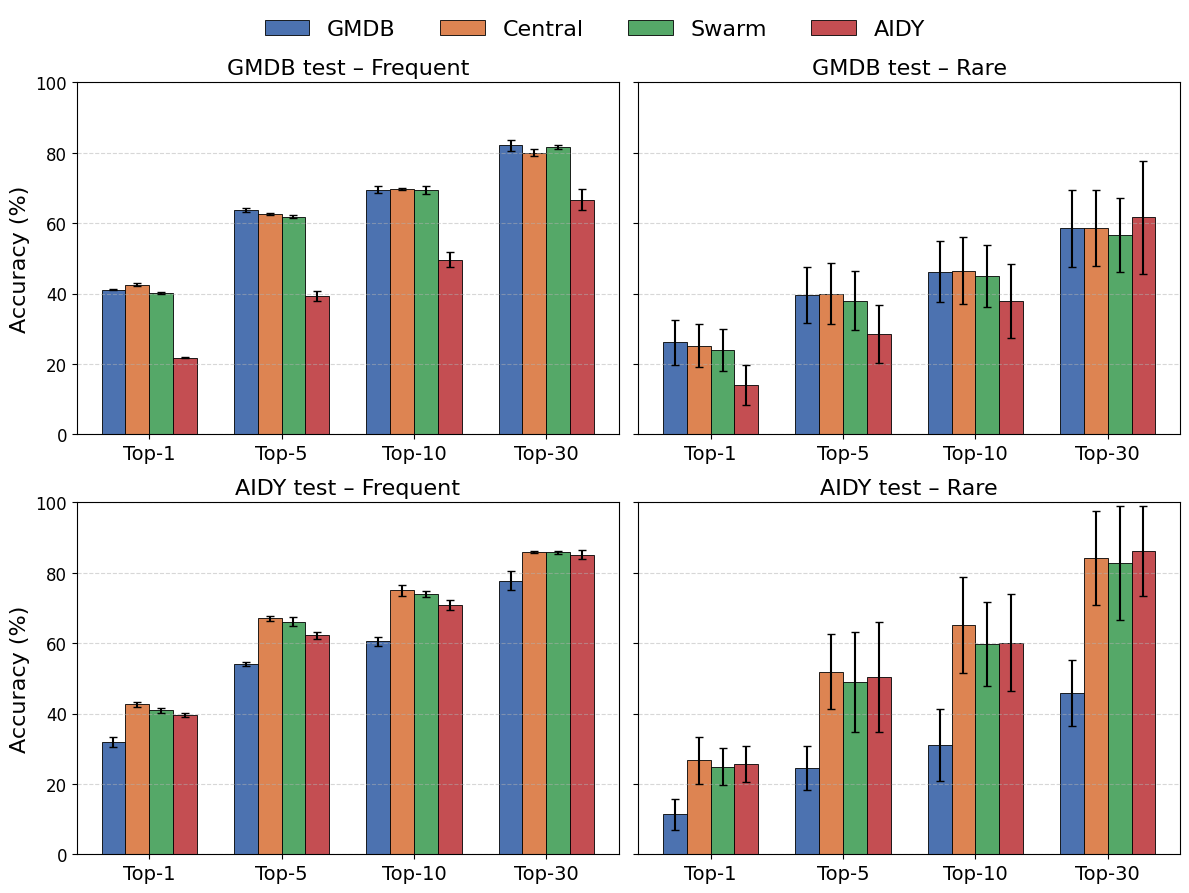

In [3]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["top1","top5","top10","top30"]
metric_labels = ["Top-1","Top-5","Top-10","Top-30"]

models = ["GMDB","Central","Swarm","AIDY"]

# consistent colors for models
colors = {
    "GMDB": "#4C72B0",
    "Central": "#DD8452",
    "Swarm": "#55A868",
    "AIDY": "#C44E52"
}

fig, axes = plt.subplots(2,2, figsize=(12,9), sharey=True)

panels = [
("GMDB","Frequent","GMDB test – Frequent"),
("GMDB","Rare","GMDB test – Rare"),
("AIDY","Frequent","AIDY test – Frequent"),
("AIDY","Rare","AIDY test – Rare")
]

width = 0.18
x = np.arange(len(metrics))

for ax,(dataset,rarity,title) in zip(axes.flatten(),panels):

    subset = plot_df[(plot_df.dataset==dataset) & (plot_df.rarity==rarity)]

    for i,model in enumerate(models):

        vals = []
        errs = []

        for metric in metrics:

            row = subset[(subset.model==model) & (subset.metric==metric)]

            vals.append(row.value.values[0])
            errs.append(row.error.values[0])

        ax.bar(
            x + i*width,
            vals,
            width,
            yerr=errs,
            capsize=3,
            color=colors[model],
            edgecolor="black",
            linewidth=0.6,
            label=model
        )

    ax.set_xticks(x + width*(len(models)-1)/2)
    ax.set_xticklabels(metric_labels,fontsize=14)
    

    ax.set_title(title, fontsize=16)

    ax.grid(axis="y", linestyle="--", alpha=0.5)
    # ax.set_yticklabels(ax.get_yticks(), fontsize=12)
    ax.tick_params(axis='y', labelsize=12)

axes[0,0].set_ylabel("Accuracy (%)", fontsize=16)
axes[1,0].set_ylabel("Accuracy (%)", fontsize=16)

# single legend for entire figure
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    frameon=False,
    fontsize=16
)

plt.ylim(0,100)


plt.tight_layout(rect=[0,0,1,0.95])

plt.savefig("model_comparison_accuracy.pdf", dpi=300, bbox_inches="tight")
plt.savefig("model_comparison_accuracy.png", dpi=300)

plt.show()

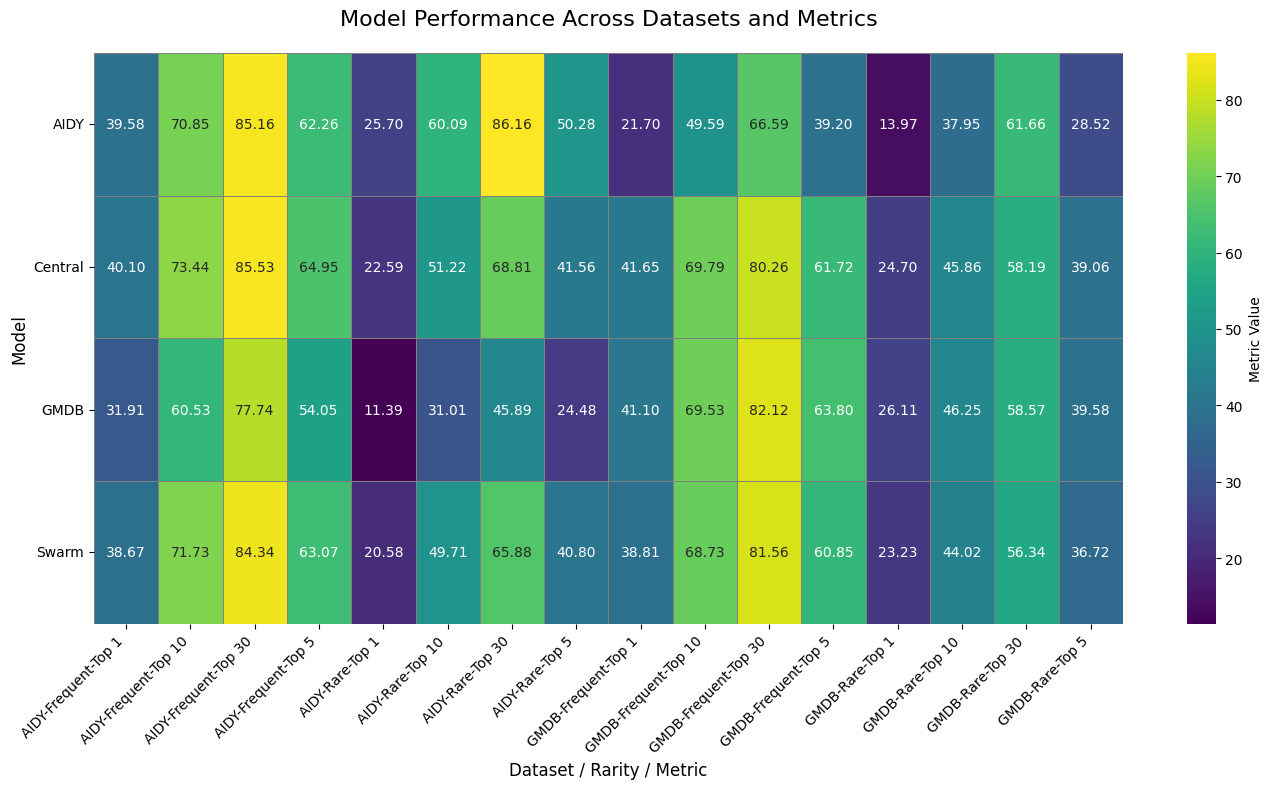

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create pivot table
pivot = plot_df.pivot_table(
    index="model",
    columns=["dataset", "rarity", "metric_label"],
    values="value"
)

# Set plot size
plt.figure(figsize=(14, 8))

# Create heatmap with nicer formatting
sns.heatmap(
    pivot,
    annot=True,                     # Show values
    fmt=".2f",                       # Format numbers
    cmap="viridis",                  # Color map
    linewidths=0.5,                  # Grid lines
    linecolor='gray',
    cbar_kws={'label': 'Metric Value'},  # Colorbar label
    square=False
)

# Improve axis labels
plt.xlabel("Dataset / Rarity / Metric", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.title("Model Performance Across Datasets and Metrics", fontsize=16, pad=20)

# Rotate column labels 
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)


plt.tight_layout()
plt.show()

/tmp/ipykernel_1186537/2502895279.py:10: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=plot_df, x="metric_label", y="value", hue="model",


Text(0, 0.5, 'Accuracy (%)')

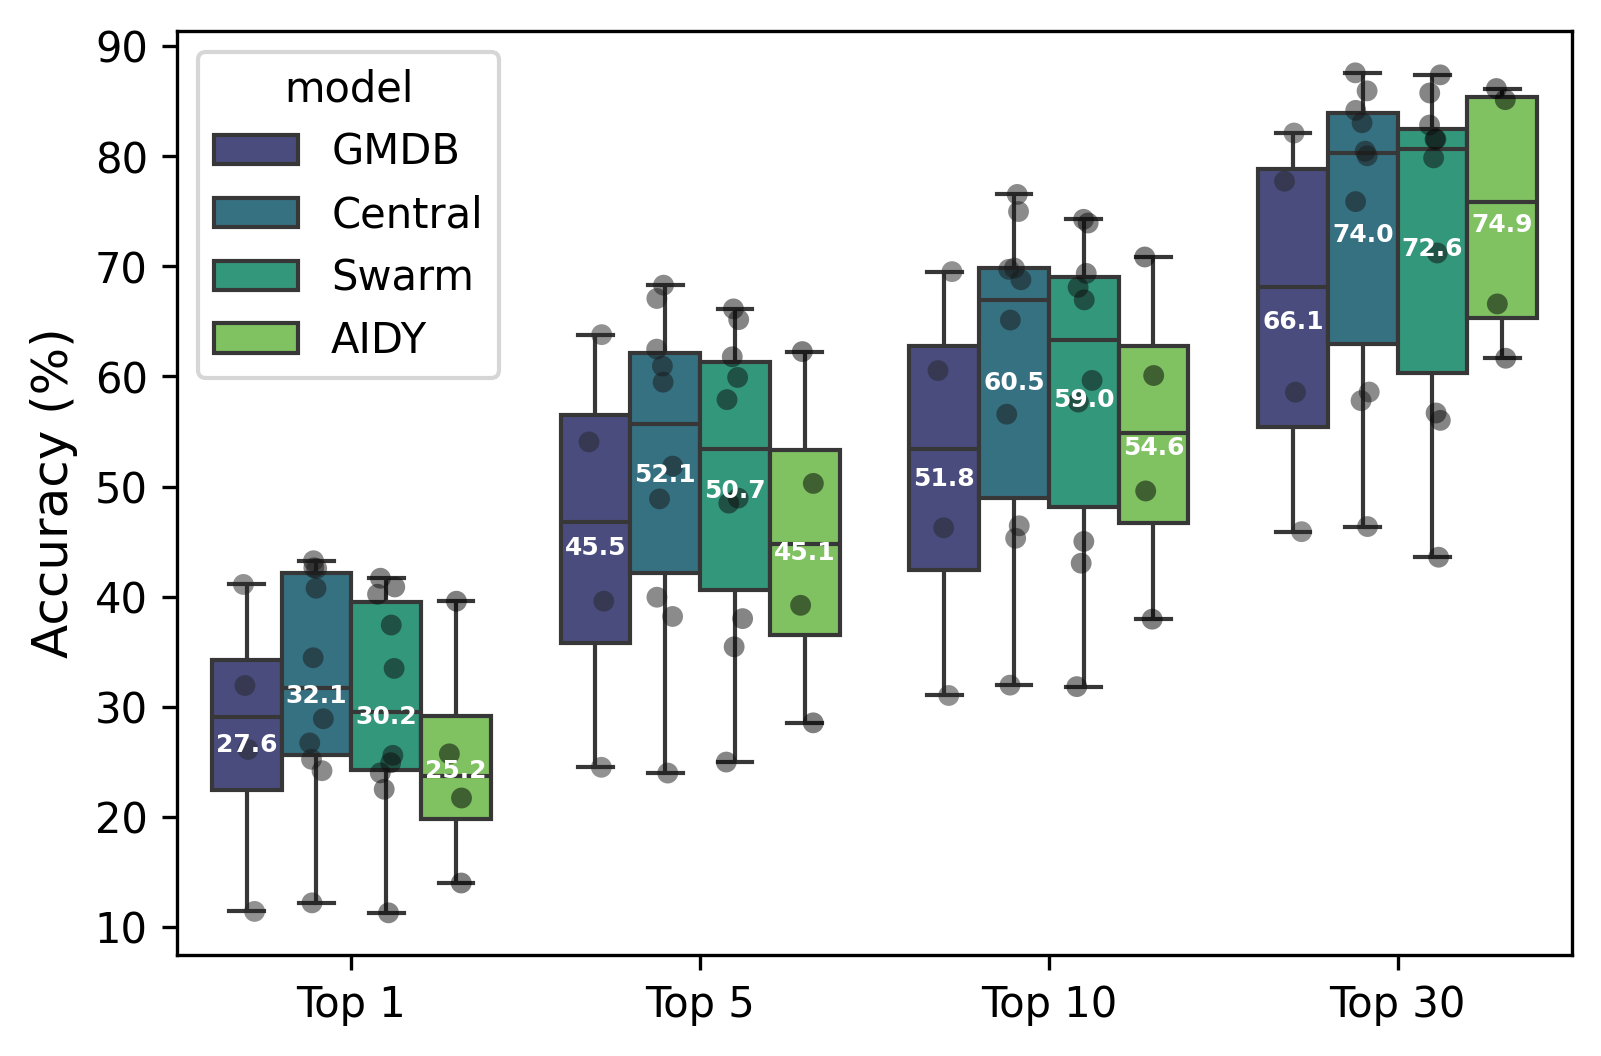

In [32]:
fig, ax = plt.subplots(figsize=(6,4), dpi=300)

sns.boxplot(
    data=plot_df,
    x="metric_label",
    y="value",
    hue="model",
    palette="viridis"
)
sns.stripplot(data=plot_df, x="metric_label", y="value", hue="model",
              dodge=True, color="black", alpha=0.5, legend=False)

grouped = plot_df.groupby(["metric_label", "model"])["value"].mean().reset_index()

for i, row in grouped.iterrows():
    x = list(plot_df["metric_label"].unique()).index(row["metric_label"])
    model_index = list(plot_df["model"].unique()).index(row["model"])
    
    ax.text(
        x + model_index*0.2 - 0.3,   # adjust for alignment
        row["value"],
        f"{row['value']:.1f}",
        ha='center',
        va='top',
        fontsize=6,
        color='white',
        fontweight='bold'
    )
    ax.set_xlabel("")
plt.ylabel("Accuracy (%)", fontsize=12)